[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB10_first_whole_brain_model.ipynb)

# Day 2 · Chapter 5 · Notebook 10 — A first whole-brain model (hands-on)

> **Your task (pairs, about 30 minutes).** Below is a working whole-brain model: one oscillator per brain region, wired
> with the connectome of NB09. Find the settings that best reproduce the measured FC, and say where they sit with
> respect to the Hopf bifurcation of NB08.
>
> **You are done when** you have (1) named the argument that sets the distance to the bifurcation and the one that
> sets the coupling, with values for "far below", "just below" and "above"; (2) a map of the similarity over these two
> knobs with the best cell marked; (3) written down on which side of the bifurcation the best fit lies, and why above
> it fails. Fast? Try the **extra tasks** at the end of section 2. Solutions: section 3 (look after trying).

**The score.** We compare two FC matrices with their **similarity**: the correlation between their values, one value
per pair of regions (upper triangle). 1 = same pattern, 0 = unrelated. It ignores the overall size of the
correlations. The connectome alone scores **0.32**: the number to beat.

In [1]:
# @title Setup: connectome, measured FC and BOLD (the data of NB09)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome, bold
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # human, 100 regions
bold_data = np.load("../data/empirical/fmri_ds000228_schaefer100.npz")["ts"]               # measured BOLD, 10 people
net = np.array([l.split("_")[2] for l in labels])                  # resting-state network of each region
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])     # regions sorted by network, for display
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]           # correlation of the upper triangles (1 = same pattern)

def show_matrix(ax, M, title, **kw):
    im = ax.imshow(M[np.ix_(order, order)], **kw); ax.set_title(title); ax.set(xticks=[], yticks=[])
    sizes = [np.sum(net == n) for n in NETS]
    for e in np.cumsum(sizes)[:-1] - 0.5: ax.axhline(e, c="k", lw=0.4); ax.axvline(e, c="k", lw=0.4)
    mids = np.cumsum([0] + sizes); ax.set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS, fontsize=7)
    return im

def dynamic_fc_variance(x, w=30, step=2):
    # dynamic FC as in NB09: band-pass like the data, FC in 60-s windows, variance of the similarity of separate windows
    x = bold.bandpass(x, 2.0)
    F = np.array([np.corrcoef(x[s:s + w].T)[u] for s in range(0, len(x) - w + 1, step)]); D = np.corrcoef(F)
    far = np.abs(np.subtract.outer(np.arange(len(F)), np.arange(len(F)))) * step >= w
    return D[np.triu(far)].var()

print(f"wiring alone vs measured FC: similarity {similarity(np.log1p(sc), fc):.2f}  <- the number to beat")

wiring alone vs measured FC: similarity 0.32  <- the number to beat


## 1. The model

Each region is the simplest oscillator with a supercritical Hopf bifurcation, the one of NB08 §1, slowed down to the
pace of BOLD (one cycle in about 20 s). Each region is pulled towards the regions it is wired to, and receives noise.
The simulator below is the whole model: **read it**, you will need it.

In [2]:
# The simulator: READ THIS CODE (your code below uses it)
def simulate(a, G, sigma=0.02, minutes=20, seed=0, f=0.05, dt=0.1, TR=2.0):
    # returns time (s) and BOLD-like signals (time x regions), one sample every TR seconds
    rng = np.random.default_rng(seed)
    N = len(sc); strength = sc.sum(1); omega = 2 * np.pi * f
    z = 0.1 * (rng.standard_normal(N) + 1j * rng.standard_normal(N))         # random start
    every, n_skip = int(TR / dt), int(60 / dt)                                # sample every TR, skip the first minute
    out = []
    for k in range(n_skip + int(minutes * 60 / dt)):
        local = (a + 1j * omega) * z - np.abs(z) ** 2 * z                      # the region itself (NB08, section 1)
        coupling = G * (sc @ z - strength * z)                                 # pulled towards connected regions
        noise = sigma * np.sqrt(dt) * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
        z = z + dt * (local + coupling) + noise                                # one time step
        if k >= n_skip and (k - n_skip) % every == every - 1:
            out.append(z.real)
    x = np.array(out)
    return np.arange(len(x)) * TR, x

def fc_similarity(a, G, sigma=0.02, runs=3, first_seed=0):
    # model FC (average of `runs` 20-minute runs) and its similarity to the measured FC
    M = np.mean([np.corrcoef(simulate(a, G, sigma, seed=s)[1].T) for s in range(first_seed, first_seed + runs)], axis=0)
    return similarity(M, fc), M

t, x = simulate(-0.5, 1.0)
print(f"{x.shape[0]} time points x {x.shape[1]} regions (20 minutes); one run takes well under a second")

600 time points x 100 regions (20 minutes); one run takes well under a second


## 2. Hands-on: find the working point

Edit the cells marked `# your code`, run them, and **write down your answer** to each question.

### Task 1 · Read the simulator (5 min)

**Question 1.** Which argument of `simulate` sets the **distance of each region to its Hopf bifurcation**? Which sets
how strongly regions pull on each other (the **coupling**)? Which the **noise**? For which values is a region below,
at, and above the bifurcation?

<details><summary>Hint</summary>

Compare the line marked "the region itself" with the Stuart–Landau oscillator of NB08 §1. Which number plays the role
of the knob there? The coupling line multiplies the whole connectome by one number.
</details>

<details><summary>Check your answer (after trying)</summary>

* `a` is the **distance to the bifurcation**: $a<0$ below (a push fades back to rest), $a=0$ at the bifurcation,
  $a>0$ above (a self-sustained rhythm).
* `G` is the **global coupling**: it scales every connection of the connectome.
* `sigma` is the **noise**.

$$\dot z_j=(a+i\omega)z_j-|z_j|^2z_j+G\sum_k W_{jk}(z_k-z_j)+\sigma\xi_j,\qquad \text{BOLD}_j\approx\mathrm{Re}\,z_j$$

$z_j$: amplitude and phase of region $j$; $\omega=2\pi\cdot0.05$ Hz; $W$: connectome (`sc`); $\xi_j$: white noise.
This is the whole-brain model of Deco et al. (2017).
</details>

### Task 2 · One region alone (7 min)

Switch the coupling off and look at one region. The black trace is the same region in a real recording.

**Question 2.** Which values of `a` are **far below**, **just below** and **above** the bifurcation? Which one looks
most like real BOLD? Compare the speed and regularity of the fluctuations, not their size (each trace is rescaled).

<details><summary>Hint: how far is "far"?</summary>

Below the bifurcation a push fades in about $1/|a|$ seconds. Compare that time with the time between two BOLD samples
(2 s) and with one cycle of the rhythm (20 s).
</details>

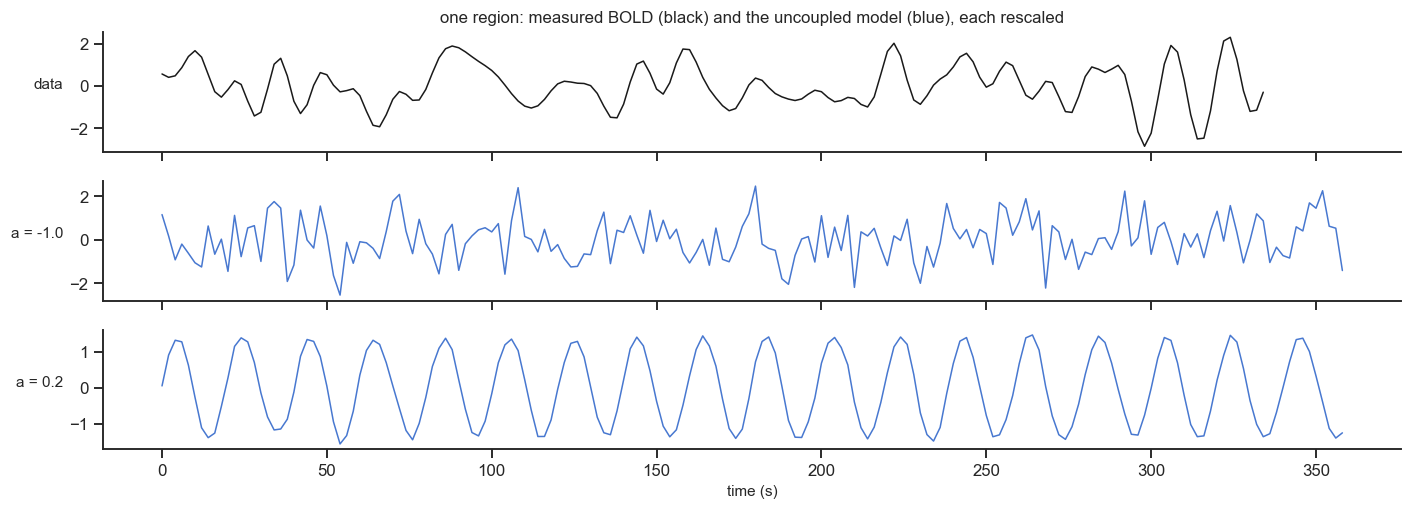

In [3]:
# your code: add values of a (e.g. between -1 and +0.3)
a_values = [-1.0, 0.2]
region = 10

fig, ax = plt.subplots(len(a_values) + 1, 1, figsize=(13, 1.6 * (len(a_values) + 1)), sharex=True)
y = bold_data[0][:, region]; ax[0].plot(np.arange(len(y)) * 2.0, y / y.std(), "k", lw=1); ax[0].set_ylabel("data", rotation=0, ha="right")
ax[0].set_title("one region: measured BOLD (black) and the uncoupled model (blue), each rescaled")
for a_, a in zip(ax[1:], a_values):
    t, x = simulate(a, G=0.0, minutes=6)
    a_.plot(t, x[:, region] / x[:, region].std(), lw=1); a_.set_ylabel(f"a = {a}", rotation=0, ha="right")
ax[-1].set_xlabel("time (s)"); plt.tight_layout(); plt.show()

### Task 3 · Couple the regions (8 min)

**Change `a` and `G`** and rerun: compare the model FC with the measured FC.

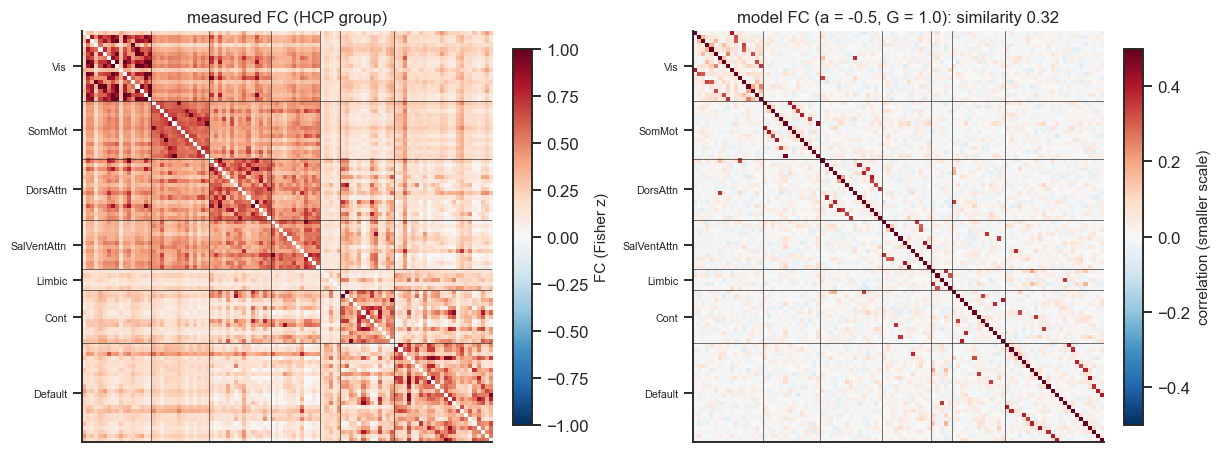

In [4]:
# your code: change a and G, then rerun
a, G = -0.5, 1.0
sim, M = fc_similarity(a, G)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
im = show_matrix(ax[0], fc, "measured FC (HCP group)", cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax[0], shrink=0.8, label="FC (Fisher z)")
im = show_matrix(ax[1], M, f"model FC (a = {a}, G = {G}): similarity {sim:.2f}", cmap="RdBu_r", vmin=-0.5, vmax=0.5)
plt.colorbar(im, ax=ax[1], shrink=0.8, label="correlation (smaller scale)")
plt.show()

With weak coupling the model FC is almost empty except for single dots: those are the direct wires, which is why it
scores about like the wiring alone. Now let a loop do it: **complete `G_values`** (0 to about 8).

**Question 3.** Does stronger coupling always help? Is there a best $G$? Does it beat the wiring alone (0.32)? Is the
gain larger than the change from one run to another? (Try `fc_similarity(a, G, first_seed=10)` at your best $G$.)

G = 0.0: similarity 0.00


G = 1.0: similarity 0.32


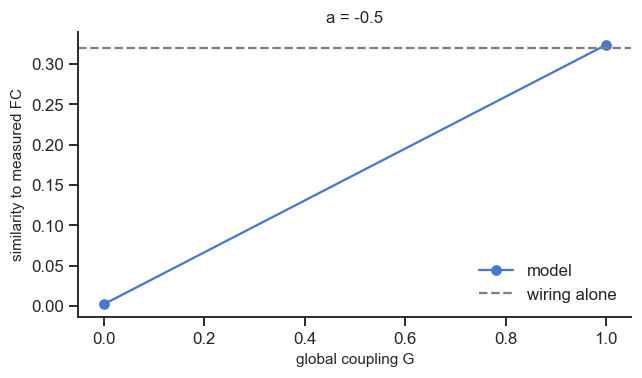

In [5]:
# your code: complete the list of couplings, e.g. 0, 0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8
a = -0.5
G_values = [0.0, 1.0]
scores = []
for G in G_values:
    s, _ = fc_similarity(a, G)
    scores.append(s); print(f"G = {G}: similarity {s:.2f}")

plt.figure(figsize=(6, 3.6))
plt.plot(G_values, scores, "o-", label="model"); plt.axhline(0.32, c="0.5", ls="--", label="wiring alone")
plt.xlabel("global coupling G"); plt.ylabel("similarity to measured FC"); plt.title(f"a = {a}"); plt.legend()
plt.tight_layout(); plt.show()

### Task 4 · Both knobs: the map (10–15 min)

**Write a double loop** over $a$ (from −1 to +0.3, with several values close to 0) and $G$ (0 to 8), store the
similarities in a table (rows $a$, columns $G$), show it as an image and **mark the best cell**. A 10 × 10 table takes
about one minute on a laptop, 2–3 minutes on Colab: let it run.

**Question 4.** Where is the best fit, relative to the bifurcation ($a=0$)? What happens at and above it, and why
(Task 2)?

**Question 5.** Follow the bright band of good fits: as you move further below the bifurcation, how must $G$ change to
stay on it? Can the FC alone tell "far below" from "just below"? Compare with your answer to Question 2.

<details><summary>Hint: the skeleton of a double loop</summary>

```python
a_list = [...]
G_list = [...]
table = np.zeros((len(a_list), len(G_list)))
for i, a in enumerate(a_list):
    for j, G in enumerate(G_list):
        table[i, j], _ = fc_similarity(a, G)
plt.imshow(table, origin="lower", aspect="auto")
plt.xticks(range(len(G_list)), G_list); plt.yticks(range(len(a_list)), a_list)
i, j = np.unravel_index(np.argmax(table), table.shape); plt.plot(j, i, "r*", ms=15)
plt.xlabel("G"); plt.ylabel("a (uneven steps)"); plt.colorbar(label="similarity"); plt.show()
```
</details>

In [6]:
# your code here

**Your answers** (double-click to edit)
1. distance to the bifurcation: … coupling: … noise: …
2. far below: a = …; just below: a = …; above: a = …; most BOLD-like: …
3. best G at a = −0.5: …; similarity …; run-to-run change …
4. best cell: a = …, G = …, similarity …; above the bifurcation the fit …
5. along the band, G … when a …

### Extra tasks (if you finish early)

**Extra 1 · Bifurcation diagram.** Plot the size of the fluctuations of one region (`x[:, 10].std()`) against $a$
(from −0.5 to 0.3) for: one region alone without noise (`G=0, sigma=0`), alone with noise (`G=0`), and inside the
network (`G=2`) with noise. Use `minutes=5`. Where does the rhythm start? What does noise do to the sharp corner of
NB08? What does the coupling do below the bifurcation?

**Extra 2 · Dynamic FC.** `dynamic_fc_variance(x)` measures how much the FC changes from minute to minute, as in NB09
(data: 0.0096). Compute it for 5 model runs as long as a recording (`simulate(a, G, minutes=5.6, seed=s)[1]`) at
$a=-0.5$ and at $a=-0.02$, each with its best $G$ from your map. Which is closer to the data? (NB13 does this on the
whole map.)

In [7]:
# your code (extra tasks)

### Stuck? Explore with sliders

In [8]:
# @title Explore: distance to the bifurcation, coupling and noise (one run per setting)
@interact(a=slider(-0.5, -1.0, 0.3, 0.02, "distance to bifurcation a"), G=slider(1.0, 0.0, 8.0, 0.25, "coupling G"),
          sigma=slider(0.02, 0.005, 0.1, 0.005, "noise σ"))
def explore_hopf_brain(a, G, sigma):
    sim, M = fc_similarity(a, G, sigma, runs=1); t, x = simulate(a, G, sigma, seed=0)
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
    for n, i in enumerate([2, 30, 85]): ax[0].plot(t[:150], x[:150, i] / x.std() + 4 * n, lw=1)
    ax[0].set(xlabel="time (s)", yticks=[], title=f"3 regions (size of fluctuations {x.std():.3f})")
    show_matrix(ax[1], M, "model FC", cmap="RdBu_r", vmin=-0.5, vmax=0.5)
    ax[2].plot(fc[u], M[u], ".", ms=1.5, c="0.4"); ax[2].set(xlabel="measured FC", ylabel="model FC", title=f"similarity {sim:.2f}")
    plt.tight_layout(); plt.show()

## 3. Solutions (look after the exercise)

Code hidden (click to show); results already computed.

**Question 1.** `a` = distance to the bifurcation (below: $a<0$, at: $a=0$, above: $a>0$), `G` = global coupling,
`sigma` = noise.

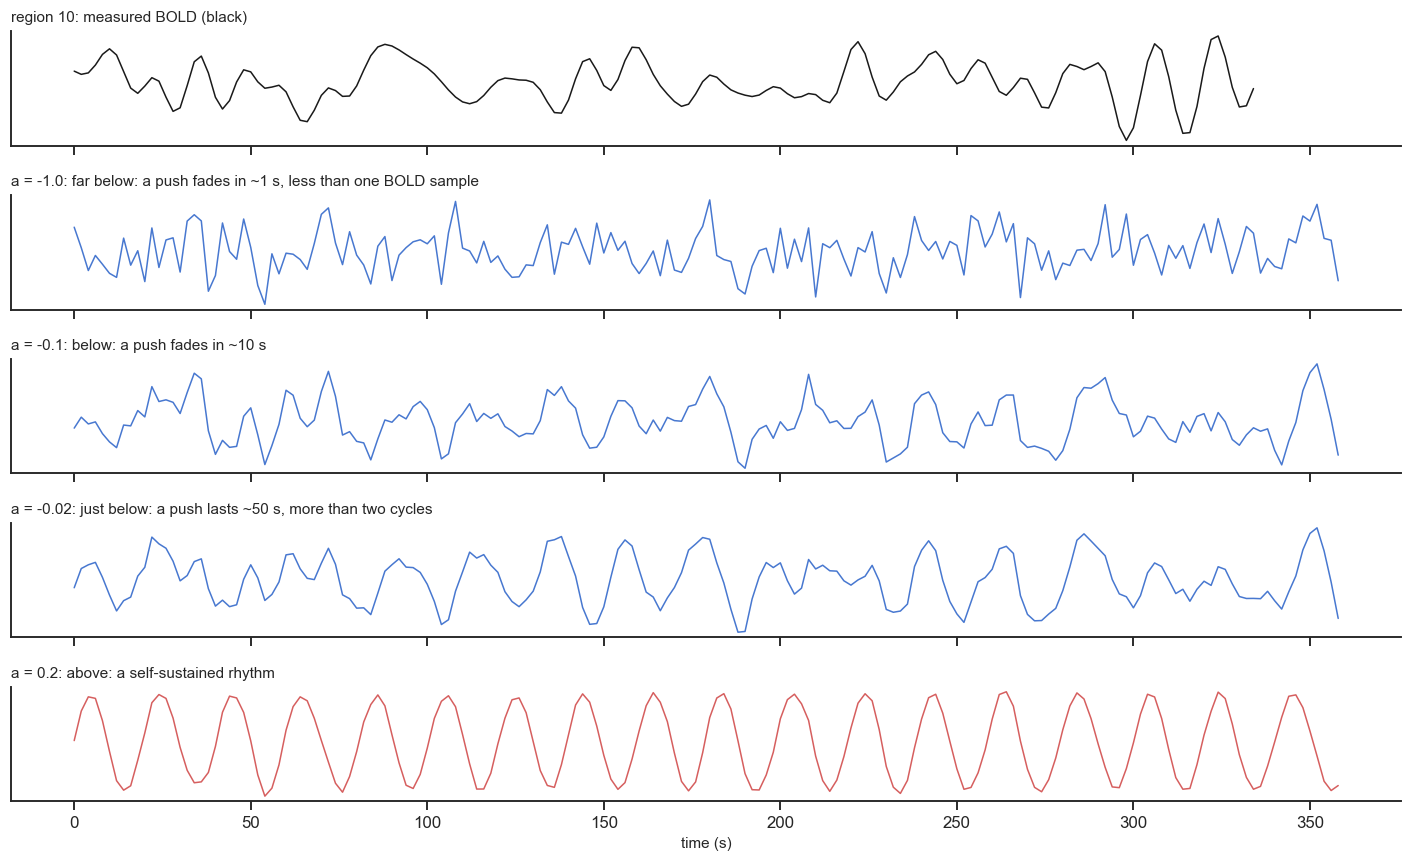

In [9]:
# @title Solution, Task 2: one region alone, far below, just below and above the bifurcation
cases = [(-1.0, "far below: a push fades in ~1 s, less than one BOLD sample"),
         (-0.1, "below: a push fades in ~10 s"),
         (-0.02, "just below: a push lasts ~50 s, more than two cycles"),
         (0.2, "above: a self-sustained rhythm")]
fig, ax = plt.subplots(len(cases) + 1, 1, figsize=(13, 8), sharex=True)
y = bold_data[0][:, 10]; ax[0].plot(np.arange(len(y)) * 2.0, y / y.std(), "k", lw=1)
ax[0].set_title("region 10: measured BOLD (black)", loc="left", fontsize=10)
for a_, (a, name) in zip(ax[1:], cases):
    t, x = simulate(a, G=0.0, minutes=6)
    a_.plot(t, x[:, 10] / x[:, 10].std(), lw=1, c="C3" if a > 0 else "C0")
    a_.set_title(f"a = {a}: {name}", loc="left", fontsize=10)
for a_ in ax: a_.set_yticks([])
ax[-1].set_xlabel("time (s)"); plt.tight_layout(); plt.show()

**Question 2.** At $a=-1$ every push is forgotten within one BOLD sample: fast, structureless jitter. At $a=-0.02$ a
push lasts about 50 s: slow, irregular waves that grow and fade, the most BOLD-like (critical slowing down, NB08).
Above the bifurcation ($a=+0.2$) the region is a clock.

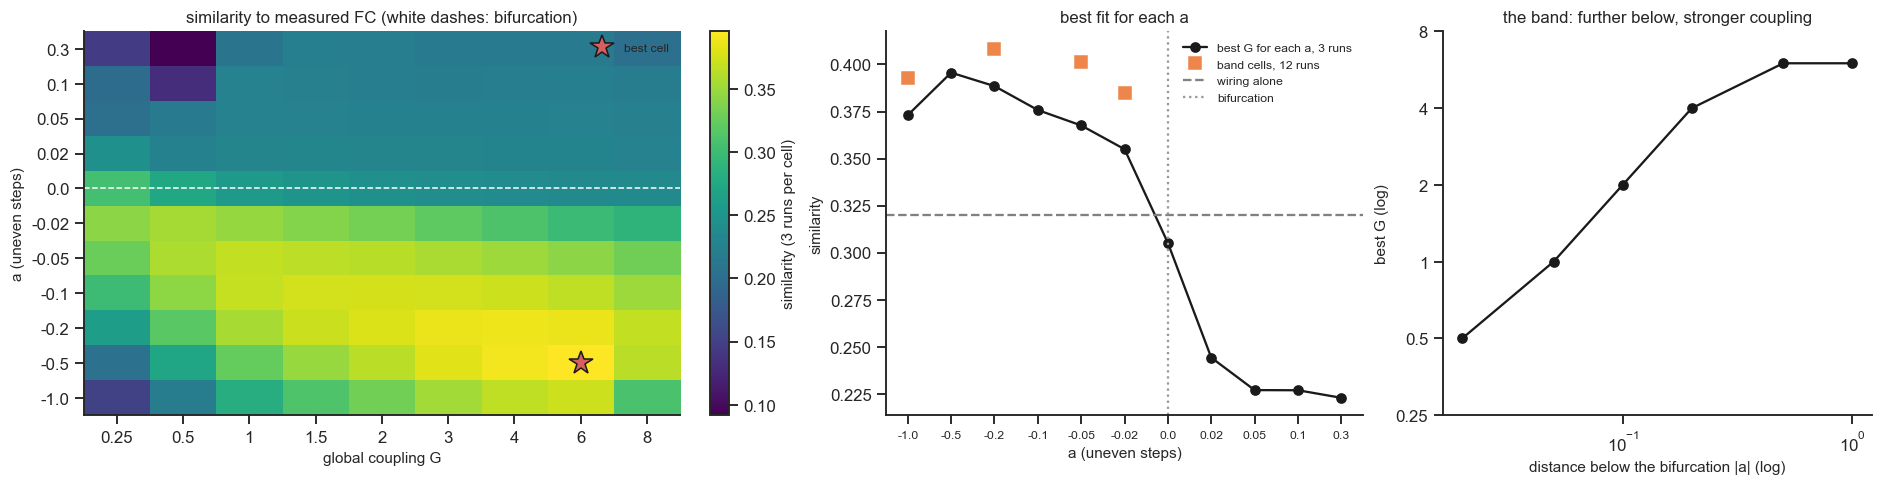

best cell of the map: a = -0.5, G = 6, similarity 0.396 (3 runs averaged)
a =  -1.0, G =    6: 12 runs averaged 0.393;  single runs 0.294 ± 0.018
a =  -0.2, G =    4: 12 runs averaged 0.408;  single runs 0.364 ± 0.021
a = -0.05, G =    1: 12 runs averaged 0.401;  single runs 0.356 ± 0.028
a = -0.02, G =    1: 12 runs averaged 0.385;  single runs 0.345 ± 0.039
at and above the bifurcation: at most 0.31


In [10]:
# @title Solution, Tasks 3-4: the map of a and G (same grid and runs as NB13), and 12-run averages along the band (about 1 min)
a_list = [-1.0, -0.5, -0.2, -0.1, -0.05, -0.02, 0.0, 0.02, 0.05, 0.1, 0.3]
G_list = [0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8]
table = np.array([[fc_similarity(a, G)[0] for G in G_list] for a in a_list])
i, j = np.unravel_index(np.argmax(table), table.shape)
band = [(-1.0, 6), (-0.2, 4), (-0.05, 1), (-0.02, 1)]                     # cells on the bright band
long_avg, single = [], []
for a, G in band:                                                         # 12 runs of 20 min = 4 hours of simulated brain
    Fs = [np.corrcoef(simulate(a, G, seed=s)[1].T) for s in range(12)]
    long_avg.append(similarity(np.mean(Fs, 0), fc)); single.append([similarity(F, fc) for F in Fs])

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw=dict(width_ratios=[1.25, 1, 0.9]), layout="constrained")
im = ax[0].imshow(table, origin="lower", aspect="auto", cmap="viridis")
ax[0].plot(j, i, "*", c="r", mec="k", ms=16, label="best cell")
ax[0].set_xticks(range(len(G_list)), [f"{g:g}" for g in G_list]); ax[0].set_yticks(range(len(a_list)), a_list)
ax[0].axhline(a_list.index(0.0), c="w", ls="--", lw=1)
ax[0].set(xlabel="global coupling G", ylabel="a (uneven steps)", title="similarity to measured FC (white dashes: bifurcation)")
ax[0].legend(fontsize=8, loc="upper right"); plt.colorbar(im, ax=ax[0], label="similarity (3 runs per cell)")
ax[1].plot(range(len(a_list)), table.max(1), "ko-", label="best G for each a, 3 runs")
ax[1].plot([a_list.index(a) for a, _ in band], long_avg, "s", c="C1", ms=8, label="band cells, 12 runs")
ax[1].axhline(0.32, c="0.5", ls="--", label="wiring alone")
ax[1].axvline(a_list.index(0.0), c="0.6", ls=":", label="bifurcation")
ax[1].set_xticks(range(len(a_list)), a_list, fontsize=8)
ax[1].set(xlabel="a (uneven steps)", ylabel="similarity", title="best fit for each a"); ax[1].legend(fontsize=8)
below = [k for k, a in enumerate(a_list) if a < 0]
ax[2].plot([-a_list[k] for k in below], [G_list[np.argmax(table[k])] for k in below], "ko-")
ax[2].set(xscale="log", yscale="log", xlabel="distance below the bifurcation |a| (log)", ylabel="best G (log)",
          title="the band: further below, stronger coupling")
ax[2].set_yticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"]); ax[2].minorticks_off()
plt.show()
print(f"best cell of the map: a = {a_list[i]}, G = {G_list[j]}, similarity {table[i, j]:.3f} (3 runs averaged)")
for (a, G), L, S in zip(band, long_avg, single):
    print(f"a = {a:5}, G = {G:4}: 12 runs averaged {L:.3f};  single runs {np.mean(S):.3f} ± {np.std(S):.3f}")
print(f"at and above the bifurcation: at most {table[a_list.index(0.0):].max():.2f}")

**Question 3.** There is a best $G$: too weak and the model FC shows only the direct wires, too strong and all regions
move together. Single 20-minute runs differ by 0.02–0.04 and score only 0.29–0.36: a finite simulation gives a noisy
FC, and noise lowers the similarity. Averaging runs removes it: with 12 runs the
model reaches about 0.40, a real gain over the wiring alone (0.32). Differences of 0.01–0.02 between neighbouring
cells of the map are noise.

**Question 4.** At and above the bifurcation the fit falls below the wiring alone: every region is a clock, they lock
together, and the wiring no longer shows. Every value of $a$ below the bifurcation can fit, with the right $G$.

**Question 5.** The good fits lie on a diagonal band: the further below the bifurcation, the stronger the coupling
needed (right panel). What sets the FC is the coupling compared with how fast each region forgets a push ($1/|a|$),
not $a$ alone. With 12 runs every cell of the band, from $a=-1$ to $a=-0.02$, reaches the same similarity (orange
squares): the "best cell" of the map is a matter of luck. So FC alone cannot tell "far below" from "just below". This
is not a contradiction with Question 2, where the time series clearly preferred "just below": NB13 adds a second
measurement, dynamic FC, to settle it.

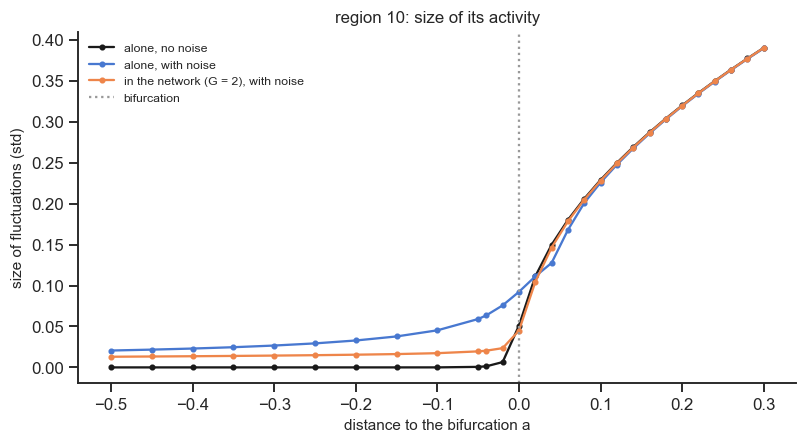

In [11]:
# @title Solution, extra 1: bifurcation diagram of one region, alone or in the network, with or without noise
aa = np.round(np.r_[np.linspace(-0.5, -0.05, 10), np.linspace(-0.04, 0.3, 18)], 3)
curves = [("alone, no noise", 0.0, 0.0, "k"), ("alone, with noise", 0.0, 0.02, "C0"), ("in the network (G = 2), with noise", 2.0, 0.02, "C1")]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, G, s, c in curves:
    ax.plot(aa, [simulate(a, G, sigma=s, minutes=5)[1][:, 10].std() for a in aa], "o-", ms=3, c=c, label=name)
ax.axvline(0, c="0.6", ls=":", label="bifurcation")
ax.set(xlabel="distance to the bifurcation a", ylabel="size of fluctuations (std)", title="region 10: size of its activity")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Extra 1.** Without noise the region is silent below $a=0$ and the rhythm grows from zero above it (the $\sqrt a$ of
NB08). Noise rounds the corner: below the bifurcation the region fluctuates, more and more as $a\to0$. In the network
the diffusive coupling damps these fluctuations below the bifurcation (each region is pulled towards its neighbours),
but the rhythm starts at the same place: the regions lock and move together.

In [12]:
# @title Solution, extra 2: dynamic FC far below and just below the bifurcation (5 runs as long as a recording)
for a in [-0.5, -0.02]:
    G = G_list[int(np.argmax(table[a_list.index(a)]))]
    v = np.mean([dynamic_fc_variance(simulate(a, G, minutes=5.6, seed=10 + s)[1]) for s in range(5)])
    print(f"a = {a:5}, best G = {G}: dynamic FC variance {v:.4f}   (data 0.0096)")

a =  -0.5, best G = 6: dynamic FC variance 0.0005   (data 0.0096)


a = -0.02, best G = 0.5: dynamic FC variance 0.0028   (data 0.0096)


**Extra 2.** Far below the bifurcation the model is far too static: every minute has the same FC. Just below it the
minute-to-minute variability grows several times, but is still below the data; NB13 shows on the whole map where it
reaches the data.

<details><summary>Discussion (open after the exercise)</summary>

* A region near its bifurcation forgets slowly: it amplifies and prolongs what it receives, so activity travels
  along the connectome and builds large-scale patterns (Deco et al. 2017).
* The FC fit fixes the side of the bifurcation (below) and the coupling relative to $|a|$, not the distance itself.
  Telling "near" from "far" needs a second property of the data: how slow the signals are (Task 2) or how much FC
  changes in time (Extra 2, NB13).
* Best fit about 0.4. For comparison, the FC of one person matches the HCP group FC at about 0.5 (NB09): a model in
  which every region is identical captures a good part, not all, of the pattern (regions that differ: NB13b).
</details>

## 4. Take-home

* A whole-brain model = **a model per region** + **connectome** + **global coupling $G$** + **noise**, compared with data.
* The model beats the wiring alone (0.32 → about 0.4, averaging enough runs): dynamics carry correlations along
  indirect paths.
* Above the bifurcation the regions lock and the fit collapses. Below it, FC fixes only the coupling relative to the
  distance; the slow, BOLD-like time series point to regions **just below** their bifurcation.
* **Next (NB13, shown right after this notebook):** the same map, pre-run, plus dynamic FC.

### Homework
*To do at home, after the class.*
1. **No connectome.** Replace `sc` by a matrix with the same weights in random positions (shuffle the upper triangle,
   then symmetrise). How much of the best fit survives?
2. **No mirror connections.** Load the connectome with `homotopic=0`. What happens to the correlations between the two
   hemispheres, and to the best fit?
3. **Different regions.** Give each region its own frequency `f` (a vector, e.g. between 0.04 and 0.07 Hz). Does the
   best working point move?

### References
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability
  and its dynamical cortical core. *Sci Rep* 7:3095.
* Honey CJ et al. (2009). Predicting human resting-state functional connectivity from structural connectivity.
  *PNAS* 106:2035–2040.
* Larivière S et al. (2021). The ENIGMA Toolbox. *Nat Methods* 18:698–700. (Connectome and FC.)
* Richardson H et al. (2018). Development of the social brain from age three to twelve years. *Nat Commun* 9:1027.
  (OpenNeuro ds000228: the BOLD of 10 adults watching a film, used in Task 2 and Extra 2.)